# Transfer learning with timm: linear probe vs. full fine-tuning

A robot rarely gets a million labelled images of the objects it must recognise. It usually
gets a few hundred or a few thousand. **Transfer learning** reuses a network pretrained on a
large dataset (here ImageNet) and adapts it to the new task with little data and compute.

This notebook compares the two standard ways of adapting a pretrained backbone on
**Imagenette-160**, a 10-class ImageNet subset with about 9.5k training images:

| strategy | what is trained | cost |
|---|---|---|
| **linear probe** | only a new linear classifier on top of frozen features | tiny: no backprop through the trunk |
| **full fine-tuning** | every weight (a smaller learning rate for the pretrained trunk) | full backprop: more time and VRAM |

The comparison covers three small backbones from [timm](https://github.com/huggingface/pytorch-image-models):
ResNet-18, EfficientNet-B0 and ConvNeXt-Nano.

**What you'll learn**
- how timm models are built, how their classifier is replaced, and how a backbone is frozen;
- a modern fine-tuning recipe: AdamW, a smaller trunk learning rate, warm-up + cosine schedule, label smoothing, bf16 autocast, `channels_last`;
- why a zero-shot ImageNet baseline is a necessary sanity check when the target data overlaps the pretraining data;
- how to read learning curves, a confusion matrix, per-class accuracy and failure cases;
- how to measure training/inference cost: wall time, throughput, latency and peak VRAM.

**Prerequisites:** PyTorch basics (modules, autograd, `DataLoader`) and a rough idea of CNNs.
Run `make data-02_representation_learning`, then the training script
`projects/02_representation_learning/scripts/train_transfer.py` (about 9 minutes on an RTX 5060 Laptop GPU).
It writes the curves and metrics that this notebook loads. Running this notebook takes about 4 minutes.

## Setup

The data pipeline, model builders and training loop are shared with the training script and
live in `projects/02_representation_learning/scripts/replearn.py`. `cvlab.device.setup()` seeds every RNG,
selects the GPU and prints the software and hardware versions, so the numbers below can be traced back to this run.

In [1]:
# --- Setup: imports, device, repo-relative paths, plotting style ---
# replearn.py holds the code shared with the training script (datasets, transforms,
# model construction, train/eval loops); we import it from the project's scripts/ folder.
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch

from cvlab import viz
from cvlab.bench import benchmark
from cvlab.device import peak_vram_mb, reset_peak_vram, setup
from cvlab.io import load_json, project_dir, repo_root, runs_dir
from cvlab.metrics import confusion_matrix

PROJECT = "02_representation_learning"
PROJ = project_dir(PROJECT)
sys.path.insert(0, str(PROJ / "scripts"))
import replearn as rl

device = setup(seed=0)
viz.set_style()
torch.backends.cudnn.benchmark = True

DATA = rl.imagenette_root()
RESULTS = PROJ / "results"
CKPTS = runs_dir(PROJECT, "transfer")


def rel(p) -> str:
    # Repo-relative path for printing (keeps machine-specific prefixes out of the outputs).
    return Path(p).resolve().relative_to(repo_root()).as_posix()


print("dataset    :", rel(DATA))
print("results    :", rel(RESULTS))
print("checkpoints:", rel(CKPTS))
print("timm", timm.__version__)

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
dataset    : data/imagenette/imagenette2-160
results    : projects/02_representation_learning/results
checkpoints: runs/02_representation_learning/transfer
timm 1.0.31


## 1. The dataset: Imagenette-160

[Imagenette](https://github.com/fastai/imagenette) (fast.ai) contains 10 easily separable ImageNet classes. The `160` variant
is resized so that the **shorter side is 160 px**, which keeps decoding cheap and the whole
dataset at a 99 MB download. Images come in the usual `ImageFolder` layout, `{train,val}/<wordnet-id>/*.JPEG`. Let's count them.

In [2]:
# --- Count images per class and split ---
# ImageFolder sorts the WordNet-id folders, so label k <-> rl.CLASS_NAMES[k].
counts = {}
for split in ["train", "val"]:
    ds = rl.make_dataset(split)
    counts[split] = np.bincount(ds.targets, minlength=len(rl.CLASS_NAMES))
counts = pd.DataFrame(counts, index=rl.CLASS_NAMES)
counts.loc["total"] = counts.sum()
counts

,train,val
tench,963,387
English springer,955,395
cassette player,993,357
chain saw,858,386
church,941,409
French horn,956,394
garbage truck,961,389
gas pump,931,419
golf ball,951,399
parachute,960,390


The classes are roughly balanced: each has 858-993 training and 357-419 validation images, so plain top-1 accuracy is
a reasonable headline metric. Below is one random training image per class, shown with the
evaluation transform: short side resized to 160 px, then a 160x160 centre crop.

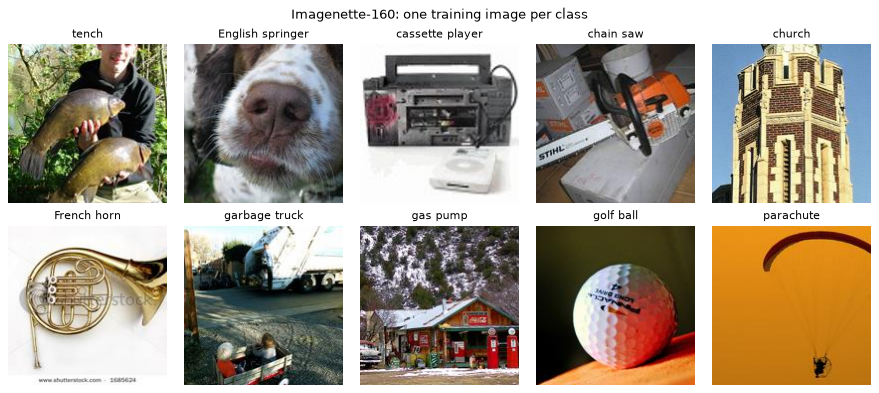

In [3]:
# --- One random training image per class (evaluation view: 160x160 centre crop) ---
rng = np.random.default_rng(0)
eval_tf = rl.build_transform(train=False, size=160)
train_raw = rl.make_dataset("train")  # PIL images, no transform
targets = np.asarray(train_raw.targets)
sample_idx = [int(rng.choice(np.flatnonzero(targets == c))) for c in range(10)]
imgs = [rl.denormalize(eval_tf(train_raw[i][0])) for i in sample_idx]
fig = viz.show_images(imgs, titles=rl.CLASS_NAMES, ncols=5, size=2.2,
                      suptitle="Imagenette-160: one training image per class")
fig.set_dpi(80)  # photo grids: lower display dpi keeps the notebook small
viz.savefig(fig, PROJECT, "imagenette_samples")
plt.show()

## 2. Data augmentation

With roughly 950 images per class, a network can memorise the training set. **Augmentation** samples a new view of
each image every epoch, so the model has to learn features that survive those changes.

- `RandomResizedCrop(160, scale=(0.35, 1))` crops a random 35-100 % of the image area with
  a random aspect ratio and resizes it to 160x160. The object therefore moves, changes scale and is sometimes partly cut off.
- `RandomHorizontalFlip()`: mirroring keeps the class label.
- Normalisation with the ImageNet mean/std $\mu=(0.485, 0.456, 0.406)$, $\sigma=(0.229, 0.224, 0.225)$
  matches the statistics the backbones were pretrained with: $x' = (x - \mu) / \sigma$.

Evaluation stays deterministic: resize the short side, then take the centre crop.

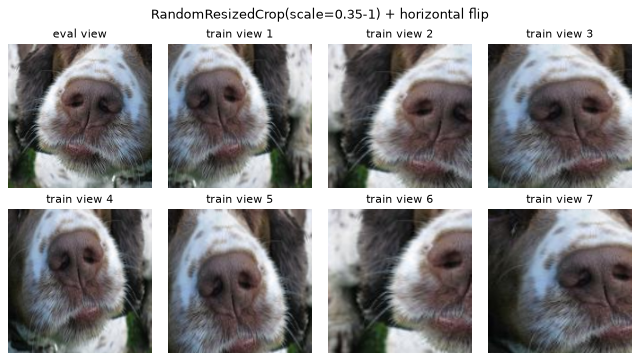

In [4]:
# --- Visualise eight random training views of the same image ---
# Each call of the train transform draws new crop/flip parameters.
train_tf = rl.build_transform(train=True, size=160)
img = train_raw[sample_idx[1]][0]  # an English springer
torch.manual_seed(0)
views = [rl.denormalize(eval_tf(img))] + [rl.denormalize(train_tf(img)) for _ in range(7)]
fig = viz.show_images(views, titles=["eval view"] + [f"train view {i}" for i in range(1, 8)],
                      ncols=4, size=2.0, suptitle="RandomResizedCrop(scale=0.35-1) + horizontal flip")
fig.set_dpi(80)
plt.show()

## 3. Two ways to reuse a pretrained network

A classifier is a **feature extractor** $f_\theta$ (the pretrained trunk) followed by a **head** $g_W$
(here one linear layer):

$$p(y \mid x) = \mathrm{softmax}\big(W\, f_\theta(x) + b\big), \qquad W \in \mathbb{R}^{C \times D}.$$

`timm.create_model(name, pretrained=True, num_classes=10)` loads the ImageNet weights and replaces
the 1000-way head with a randomly initialised 10-way one.

- **Linear probe**: freeze $\theta$ and learn only $(W, b)$, that is $C(D+1)$ numbers. For fixed features the loss
  is convex in $W$. The trunk can run under `torch.no_grad()`, so no activations are stored for
  backprop. The trunk also stays in `eval()` mode, which freezes its BatchNorm statistics.
- **Full fine-tuning**: learn $\theta$ and $W$ together. The new head starts random, so its early gradients are
  noisy. To avoid wrecking the pretrained features we give the trunk a **10x smaller learning rate**
  (head $2\cdot10^{-3}$, trunk $2\cdot10^{-4}$) and use a half-epoch linear **warm-up** followed by a **cosine** decay.

Both use AdamW (weight decay 0.05) and cross-entropy with **label smoothing** $\epsilon = 0.1$, which trains toward
the softened target $q_c = (1-\epsilon)\,\mathbb{1}[c=y] + \epsilon / C$ instead of a one-hot vector:
$\mathcal{L} = -\sum_c q_c \log p_c$. The table shows how many parameters each strategy trains.

In [5]:
# --- Build every backbone in both modes and count (trainable) parameters ---
# build_model(..., "linear_probe") calls requires_grad_(False) on everything except the head.
rows = []
for name in rl.BACKBONES:
    for mode in rl.MODES:
        m = rl.build_model(name, mode)
        total, trainable = rl.count_params(m)
        rows.append({"backbone": name, "mode": mode, "feature dim D": m.num_features,
                     "params total [M]": round(total / 1e6, 2), "params trainable": trainable,
                     "trainable [%]": round(100 * trainable / total, 3)})
del m
pd.DataFrame(rows)

,backbone,mode,feature dim D,params total [M],params trainable,trainable [%]
0,resnet18.a1_in1k,linear_probe,512,11.18,5130,0.046
1,resnet18.a1_in1k,finetune,512,11.18,11181642,100.000
2,efficientnet_b0.ra_in1k,linear_probe,1280,4.02,12810,0.319
3,efficientnet_b0.ra_in1k,finetune,1280,4.02,4020358,100.000
4,convnext_nano.in12k_ft_in1k,linear_probe,640,14.96,6410,0.043
5,convnext_nano.in12k_ft_in1k,finetune,640,14.96,14958970,100.000


## 4. Zero-shot sanity check: the ImageNet head already knows these classes

Imagenette's images are drawn from ImageNet, and every class is one of the 1000 ImageNet-1k classes, so these backbones were
pretrained *with labels for exactly these classes*. Before training anything, it is worth asking how
well the **original 1000-way ImageNet classifier** does when we keep only the 10 Imagenette logits
($\hat y = \arg\max_{k \in \mathcal{I}} z_k$ over the 10 ImageNet indices $\mathcal{I}$).

This baseline needs no training. It tells us how much of the accuracy below is really *learned on Imagenette*
and how much is *inherited*. With your own robot data, which no public model has seen, you should not expect the
pretrained features to be this good out of the box.

In [6]:
# --- Evaluate the untouched ImageNet-1k classifiers on the Imagenette val split ---
# "restricted": argmax over the 10 relevant ImageNet logits; "1000-way": the unrestricted
# top-1 prediction must be exactly the right ImageNet class.
val_ds = rl.make_dataset("val", eval_tf)
val_dl = rl.make_loader(val_ds, batch_size=256, workers=8)
zero_shot = {}
for name in rl.BACKBONES:
    m = timm.create_model(name, pretrained=True).to(device).to(memory_format=torch.channels_last)
    logits, y_val = rl.predict(m, val_dl, device)  # (N, 1000) logits, (N,) labels
    restricted = float((logits[:, rl.IMAGENET1K_INDEX].argmax(1) == y_val).mean())
    full = float((logits.argmax(1) == np.asarray(rl.IMAGENET1K_INDEX)[y_val]).mean())
    zero_shot[name] = {"restricted to 10 classes": restricted, "1000-way top-1": full}
    del m
torch.cuda.empty_cache()
pd.DataFrame(zero_shot).T.style.format("{:.2%}")

,restricted to 10 classes,1000-way top-1
resnet18.a1_in1k,97.04%,67.08%
efficientnet_b0.ra_in1k,98.93%,73.07%
convnext_nano.in12k_ft_in1k,99.57%,78.85%


## 5. The training runs

Training happens in `scripts/train_transfer.py` and not in this notebook: six runs (3 backbones x 2 modes) take about 9 minutes,
and a notebook should stay short and re-runnable. The script was run once with

```bash
flock /tmp/cv-gpu.lock python projects/02_representation_learning/scripts/train_transfer.py
```

using 10 epochs, batch 128, 160 px, bf16 autocast and seed 0. Each run writes a JSON file with per-epoch curves, wall time,
throughput and the peak VRAM of the training steps (`torch.cuda.max_memory_allocated`). Let's load those files.

In [7]:
# --- Load the per-run JSON results written by the training script ---
runs = {}
for name in rl.BACKBONES:
    for mode in rl.MODES:
        runs[(name, mode)] = load_json(RESULTS / "transfer" / f"{name}__{mode}.json")
train_table = pd.DataFrame([{
    "backbone": r["model"], "mode": r["mode"], "trainable params": r["params_trainable"],
    "final val acc": r["final_val_acc"], "best val acc": r["best_val_acc"],
    "train time [s]": r["train_time_s"], "train throughput [img/s]": r["mean_train_imgs_per_s"],
    "peak train VRAM [MiB]": r["peak_vram_train_mb"]} for r in runs.values()])
print("GPU:", runs[(rl.BACKBONES[0], "finetune")]["env"]["gpu"],
      "| epochs:", runs[(rl.BACKBONES[0], "finetune")]["epochs"])
train_table.style.format({"final val acc": "{:.2%}", "best val acc": "{:.2%}",
                          "train time [s]": "{:.0f}", "train throughput [img/s]": "{:.0f}",
                          "peak train VRAM [MiB]": "{:.0f}"})

GPU: NVIDIA GeForce RTX 5060 Laptop GPU | epochs: 10


,backbone,mode,trainable params,final val acc,best val acc,train time [s],train throughput [img/s],peak train VRAM [MiB]
0,resnet18.a1_in1k,linear_probe,5130,97.07%,97.12%,42,4689,451
1,resnet18.a1_in1k,finetune,11181642,97.43%,97.43%,63,1822,1003
2,efficientnet_b0.ra_in1k,linear_probe,12810,95.90%,95.90%,77,3897,1084
3,efficientnet_b0.ra_in1k,finetune,4020358,96.59%,96.66%,118,1085,2909
4,convnext_nano.in12k_ft_in1k,linear_probe,6410,99.41%,99.41%,87,1954,845
5,convnext_nano.in12k_ft_in1k,finetune,14958970,98.90%,98.90%,148,778,2817


## 6. Re-evaluate the saved checkpoints

The script saved the final weights of every run to `runs/02_representation_learning/transfer/`. That folder is gitignored,
so you need to run the training script first. We reload all six checkpoints and predict on the 3,925 validation images. The predictions feed the
confusion matrix and the failure analysis, and they also check that the checkpoints reproduce the logged accuracy.
Small differences of a few images are possible because bf16 cuDNN kernels can be picked differently from run to run.

In [8]:
# --- Load each checkpoint (weights_only=True: tensors only, no pickled code) and predict ---
val_logits = {}
for (name, mode), r in runs.items():
    m = rl.build_model(name, mode, pretrained=False)
    m.load_state_dict(torch.load(repo_root() / r["checkpoint"], map_location="cpu", weights_only=True))
    m = m.to(device).to(memory_format=torch.channels_last)
    val_logits[(name, mode)], y_val = rl.predict(m, val_dl, device)
    acc = (val_logits[(name, mode)].argmax(1) == y_val).mean()
    print(f"{name:28s} {mode:13s} logged {r['final_val_acc']:.4f} | re-evaluated {acc:.4f}")
    del m
torch.cuda.empty_cache()

resnet18.a1_in1k             linear_probe  logged 0.9707 | re-evaluated 0.9707


resnet18.a1_in1k             finetune      logged 0.9743 | re-evaluated 0.9743


efficientnet_b0.ra_in1k      linear_probe  logged 0.9590 | re-evaluated 0.9590


efficientnet_b0.ra_in1k      finetune      logged 0.9659 | re-evaluated 0.9659


convnext_nano.in12k_ft_in1k  linear_probe  logged 0.9941 | re-evaluated 0.9941


convnext_nano.in12k_ft_in1k  finetune      logged 0.9890 | re-evaluated 0.9890


## 7. Inference cost: latency, throughput and memory

On a robot the deployed model's speed matters as much as its accuracy. GPU kernels run
**asynchronously**, so a timer must call `torch.cuda.synchronize()` before reading the clock. `cvlab.bench.benchmark`
does this. We measure

- **latency** at batch 1 (one camera frame), in ms;
- **throughput** at batch 128, in images per second;
- **peak VRAM** after warm-up, which excludes the one-off cuDNN autotuning workspace.

All three use bf16 autocast and `channels_last` at 160x160 px on the fine-tuned models. Linear-probe models have the same
architecture and the same inference cost.

In [9]:
# --- Benchmark the fine-tuned models (bf16 autocast, channels_last, 160x160 input) ---
def bench_model(model, batch):
    x = torch.randn(batch, 3, 160, 160, device=device).contiguous(memory_format=torch.channels_last)

    @torch.no_grad()
    def step():
        with torch.autocast("cuda", dtype=torch.bfloat16):
            return model(x)

    for _ in range(15):  # warm-up: cuDNN autotuning happens here
        step()
    reset_peak_vram()
    stats = benchmark(step, warmup=5, iters=50)
    stats["peak_vram_mb"] = peak_vram_mb()
    return stats

infer = {}
for name in rl.BACKBONES:
    m = rl.build_model(name, "finetune", pretrained=False).to(device).eval()
    m = m.to(memory_format=torch.channels_last)
    b1, b128 = bench_model(m, 1), bench_model(m, 128)
    infer[name] = {"latency bs1 [ms]": b1["mean_ms"], "p90 bs1 [ms]": b1["p90_ms"],
                   "throughput bs128 [img/s]": 128 * b128["fps"],
                   "peak VRAM bs128 [MiB]": b128["peak_vram_mb"]}
    del m
torch.cuda.empty_cache()
pd.DataFrame(infer).T.style.format("{:.1f}")

,latency bs1 [ms],p90 bs1 [ms],throughput bs128 [img/s],peak VRAM bs128 [MiB]
resnet18.a1_in1k,1.4,1.4,6045.9,317.5
efficientnet_b0.ra_in1k,4.9,5.2,5154.1,438.6
convnext_nano.in12k_ft_in1k,2.7,3.2,2245.3,545.3


## Results

### Learning curves

Validation accuracy and training loss per epoch for all six runs, with solid lines for fine-tuning and dashed lines for the linear probe.
The training loss includes label smoothing, so it cannot reach 0. With $\epsilon=0.1$ and $C=10$ its floor is the entropy of
the smoothed target, about 0.5.

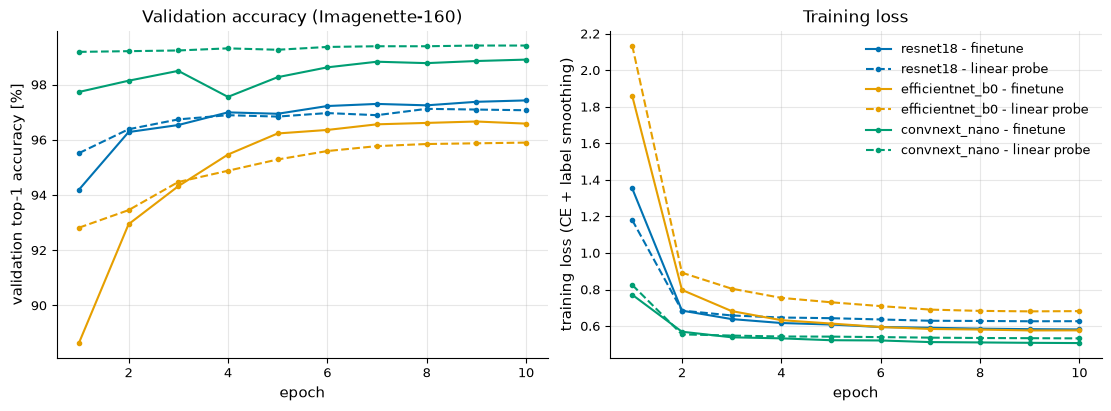

In [10]:
# --- Plot validation accuracy and training loss per epoch for all runs ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i, name in enumerate(rl.BACKBONES):
    for mode, ls in [("finetune", "-"), ("linear_probe", "--")]:
        h = pd.DataFrame(runs[(name, mode)]["history"])
        label = f"{name.split('.')[0]} - {mode.replace('_', ' ')}"
        axes[0].plot(h["epoch"], 100 * h["val_acc"], ls, color=viz.color(i, unit=True), marker="o", ms=3, label=label)
        axes[1].plot(h["epoch"], h["train_loss"], ls, color=viz.color(i, unit=True), marker="o", ms=3, label=label)
axes[0].set(xlabel="epoch", ylabel="validation top-1 accuracy [%]", title="Validation accuracy (Imagenette-160)")
axes[1].set(xlabel="epoch", ylabel="training loss (CE + label smoothing)", title="Training loss")
axes[1].legend(ncols=1, loc="upper right")
viz.savefig(fig, PROJECT, "learning_curves")
plt.show()

### Accuracy vs. cost

Final validation accuracy next to what it cost: training wall time and peak training VRAM. The grey bars are
the zero-shot ImageNet head from section 4, which needs no training.

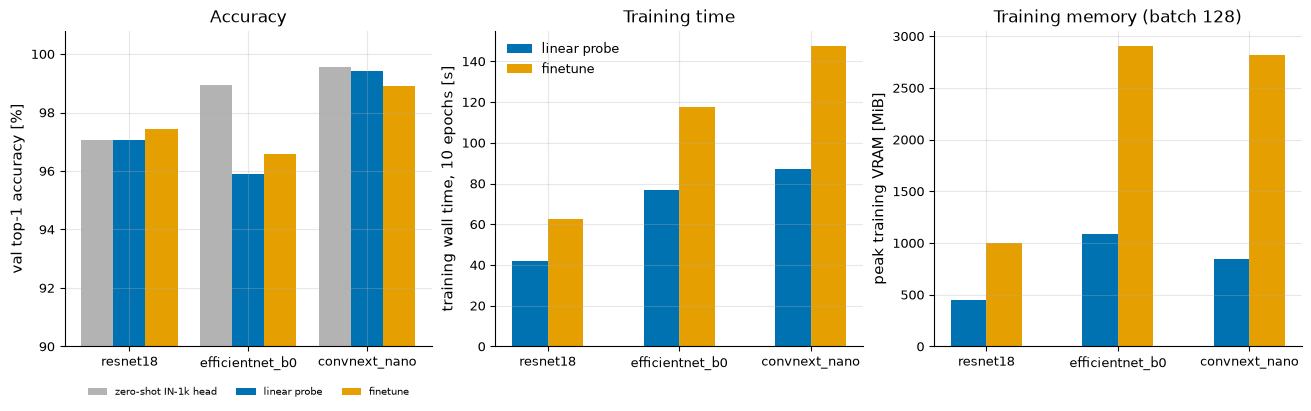

In [11]:
# --- Grouped bars: accuracy (incl. zero-shot), training time and training VRAM per backbone ---
short = [n.split(".")[0] for n in rl.BACKBONES]
xs = np.arange(len(rl.BACKBONES))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
acc_zs = [100 * zero_shot[n]["restricted to 10 classes"] for n in rl.BACKBONES]
axes[0].bar(xs - 0.27, acc_zs, 0.27, color="0.7", label="zero-shot IN-1k head")
for k, (mode, off) in enumerate([("linear_probe", 0.0), ("finetune", 0.27)]):
    acc = [100 * runs[(n, mode)]["final_val_acc"] for n in rl.BACKBONES]
    tt = [runs[(n, mode)]["train_time_s"] for n in rl.BACKBONES]
    vr = [runs[(n, mode)]["peak_vram_train_mb"] for n in rl.BACKBONES]
    c = viz.color(k, unit=True)
    lab = mode.replace("_", " ")
    axes[0].bar(xs + off, acc, 0.27, color=c, label=lab)
    axes[1].bar(xs + off - 0.135, tt, 0.27, color=c, label=lab)
    axes[2].bar(xs + off - 0.135, vr, 0.27, color=c, label=lab)
axes[0].set(ylim=(90, 100.8), ylabel="val top-1 accuracy [%]", title="Accuracy")
axes[1].set(ylabel="training wall time, 10 epochs [s]", title="Training time")
axes[2].set(ylabel="peak training VRAM [MiB]", title="Training memory (batch 128)")
for ax in axes:
    ax.set_xticks(xs, short)
axes[0].legend(loc="upper center", ncols=3, fontsize=7, bbox_to_anchor=(0.5, -0.1))
axes[1].legend()
viz.savefig(fig, PROJECT, "accuracy_vs_cost")
plt.show()

### Confusion matrix and per-class accuracy

The confusion matrix $C_{ij}$ counts validation images of true class $i$ predicted as class $j$. We
normalise each row, so the diagonal is the per-class recall. Below is the matrix of the fine-tuned ResNet-18,
the model whose decisions notebook 03 explains with Grad-CAM, next to the per-class accuracy of all three fine-tuned backbones.

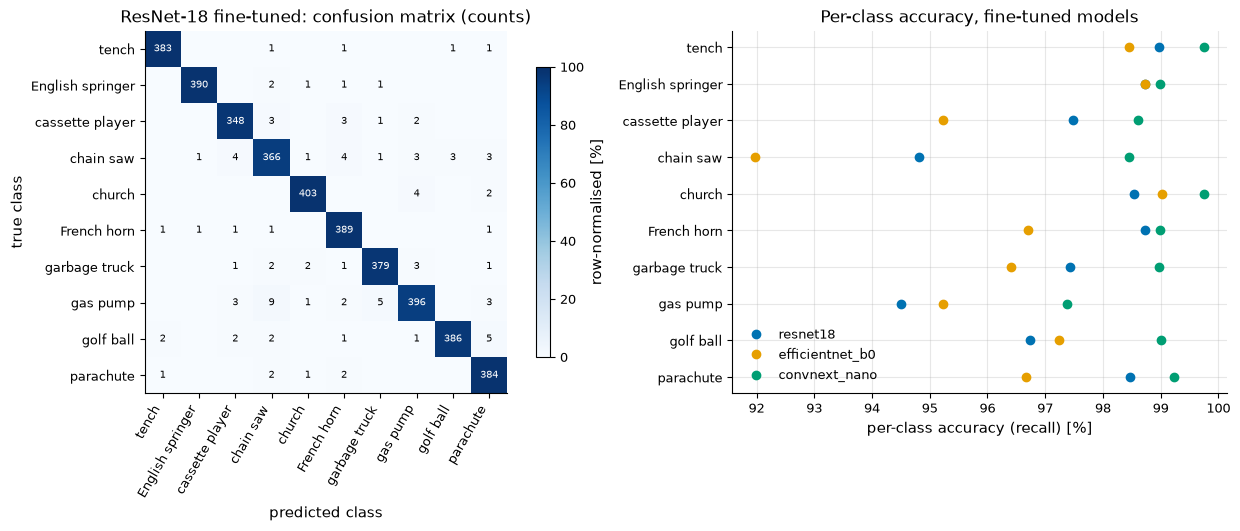

In [12]:
# --- Row-normalised confusion matrix (ResNet-18, fine-tuned) + per-class accuracy ---
ref = (rl.BACKBONES[0], "finetune")
pred_ref = val_logits[ref].argmax(1)
cm = confusion_matrix(y_val, pred_ref, n_classes=10)
cm_norm = cm / cm.sum(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(100 * cm_norm, cmap="Blues", vmin=0, vmax=100)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            axes[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                         color="white" if cm_norm[i, j] > 0.5 else "black")
axes[0].set_xticks(range(10), rl.CLASS_NAMES, rotation=60, ha="right")
axes[0].set_yticks(range(10), rl.CLASS_NAMES)
axes[0].set(xlabel="predicted class", ylabel="true class", title="ResNet-18 fine-tuned: confusion matrix (counts)")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], label="row-normalised [%]", shrink=0.8)
per_class = {}
for i, name in enumerate(rl.BACKBONES):
    p = val_logits[(name, "finetune")].argmax(1)
    per_class[name.split(".")[0]] = [100 * (p[y_val == c] == c).mean() for c in range(10)]
    axes[1].plot(per_class[name.split(".")[0]], range(10), "o", color=viz.color(i, unit=True),
                 label=name.split(".")[0])
axes[1].set_yticks(range(10), rl.CLASS_NAMES)
axes[1].invert_yaxis()
axes[1].set(xlabel="per-class accuracy (recall) [%]", title="Per-class accuracy, fine-tuned models")
axes[1].legend(loc="lower left")
viz.savefig(fig, PROJECT, "confusion_matrix")
plt.show()

### Failure cases

Aggregate metrics hide *why* a model fails. Here are the ResNet-18 validation errors with the highest confidence in the wrong class, shown with
the true label and the predicted label and probability. Before blaming the model, check whether the labelled object is
clearly visible and typical.

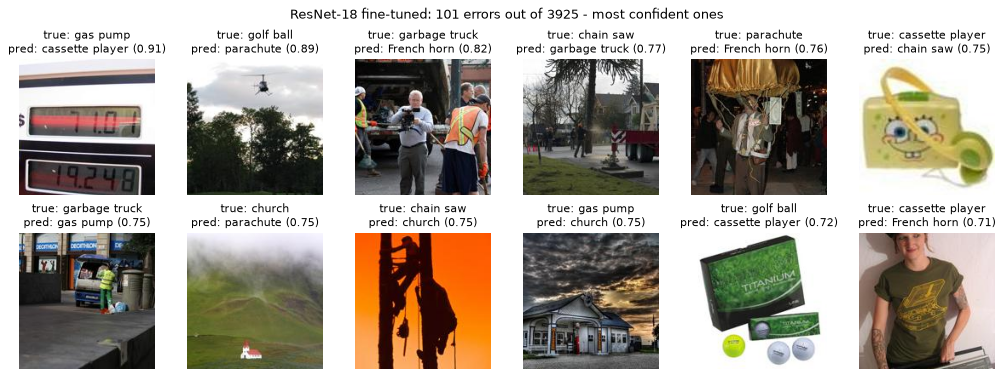

In [13]:
# --- Most confident mistakes of the fine-tuned ResNet-18 ---
prob = torch.from_numpy(val_logits[ref]).softmax(1).numpy()
wrong = np.flatnonzero(pred_ref != y_val)
worst = wrong[np.argsort(-prob[wrong, pred_ref[wrong]])][:12]
imgs = [rl.denormalize(val_ds[i][0]) for i in worst]
titles = [f"true: {rl.CLASS_NAMES[y_val[i]]}\npred: {rl.CLASS_NAMES[pred_ref[i]]} ({prob[i, pred_ref[i]]:.2f})"
          for i in worst]
fig = viz.show_images(imgs, titles=titles, ncols=6, size=2.1,
                      suptitle=f"ResNet-18 fine-tuned: {len(wrong)} errors out of {len(y_val)} - most confident ones")
fig.set_dpi(80)
viz.savefig(fig, PROJECT, "failures")
plt.show()

### Summary table

All measured numbers in one place: accuracy from the checkpoints re-evaluated in section 6, training cost from the
training-script JSON and inference cost from section 7. The hardware is an RTX 5060 Laptop GPU with 8 GB, using bf16 autocast at 160 px.

In [14]:
# --- Assemble the summary DataFrame of everything measured above ---
rows = []
for name in rl.BACKBONES:
    acc = {m: (val_logits[(name, m)].argmax(1) == y_val).mean() for m in rl.MODES}
    rows.append({
        "backbone": name,
        "zero-shot IN-1k head": zero_shot[name]["restricted to 10 classes"],
        "linear probe acc": acc["linear_probe"],
        "fine-tune acc": acc["finetune"],
        "LP train time [s]": runs[(name, "linear_probe")]["train_time_s"],
        "FT train time [s]": runs[(name, "finetune")]["train_time_s"],
        "LP train VRAM [MiB]": runs[(name, "linear_probe")]["peak_vram_train_mb"],
        "FT train VRAM [MiB]": runs[(name, "finetune")]["peak_vram_train_mb"],
        "latency bs1 [ms]": infer[name]["latency bs1 [ms]"],
        "throughput bs128 [img/s]": infer[name]["throughput bs128 [img/s]"],
        "inference VRAM bs128 [MiB]": infer[name]["peak VRAM bs128 [MiB]"],
    })
summary = pd.DataFrame(rows).set_index("backbone")
pct = ["zero-shot IN-1k head", "linear probe acc", "fine-tune acc"]
summary.style.format({c: "{:.2%}" for c in pct} | {c: "{:.1f}" for c in summary.columns if c not in pct})

,zero-shot IN-1k head,linear probe acc,fine-tune acc,LP train time [s],FT train time [s],LP train VRAM [MiB],FT train VRAM [MiB],latency bs1 [ms],throughput bs128 [img/s],inference VRAM bs128 [MiB]
backbone,,,,,,,,,,
resnet18.a1_in1k,97.04%,97.07%,97.43%,41.9,62.5,451.3,1003.0,1.4,6045.9,317.5
efficientnet_b0.ra_in1k,98.93%,95.90%,96.59%,76.6,117.6,1083.7,2908.7,4.9,5154.1,438.6
convnext_nano.in12k_ft_in1k,99.57%,99.41%,98.90%,87.1,147.7,845.1,2816.7,2.7,2245.3,545.3


### Takeaways

- **Check the zero-shot baseline first.** With no training at all, the original ImageNet-1k heads restricted to the 10 Imagenette
  logits score 97.04 % (ResNet-18), 98.93 % (EfficientNet-B0) and 99.57 % (ConvNeXt-Nano). For EfficientNet-B0 and ConvNeXt-Nano
  this beats *both* of our trained heads. Imagenette is drawn from ImageNet, so these backbones were trained with labels for exactly
  these classes. The numbers in this notebook measure how well a new 10-way head re-learns known classes from 9.5k small images.
  They say little about transfer to a robot's own objects.
- **Linear probe vs. fine-tuning depends on the backbone.** Fine-tuning gained on ResNet-18 (97.07 % → 97.43 %) and EfficientNet-B0
  (95.90 % → 96.59 %) but *lost* on ConvNeXt-Nano (99.41 % → 98.90 %). When the pretrained features already separate the classes,
  updating them with a small dataset can make things worse (Kumar et al., 2022).
- **Linear probing is cheaper, but by less than you might expect.** It trains only 0.04-0.32 % of the weights and needed 2.2-3.3x
  less peak training VRAM (for example 845 vs. 2817 MiB for ConvNeXt-Nano), yet only 1.5-1.7x less wall time: every epoch still
  runs the frozen trunk forward on freshly augmented images. Caching the features once, as notebook 02 does, removes that cost.
- **Parameter count is a poor proxy for speed.** EfficientNet-B0 has the fewest parameters (4.0 M) but the highest batch-1 latency
  (4.9 ms vs. 1.4 ms for ResNet-18), because its many small depthwise layers are launch-bound at batch 1. ResNet-18 also has the
  highest batch-128 throughput (6046 img/s).
- **Look at the errors, not just the accuracy.** The fine-tuned ResNet-18 makes 101 errors on 3,925 images, and gas pump and chain saw
  are its weakest classes. Many of the most confident mistakes are ambiguous or questionable images: a tiny church in a valley, a
  "golf ball" photo that shows a helicopter, a cassette player printed on a T-shirt. Notebook 03 inspects them with Grad-CAM.

## Exercises

Solutions: `projects/02_representation_learning/solutions/01_transfer_learning_solutions.py`.

**Exercise 1: partial fine-tuning.** Between "freeze everything" and "train everything" lies *partial* fine-tuning.
Unfreeze only the last stage of ResNet-18 (`model.layer4`) plus the head, train for 3 epochs, and compare the accuracy,
trainable parameters, time and peak VRAM with the two runs above. One subtlety: `model.train()` would also update the running
BatchNorm statistics of the *frozen* layers. Adapt the loop of `rl.train_one_epoch` so that it calls `model.train()` and then puts the
frozen stem and `layer1`-`layer3` back into `eval()` mode.

In [15]:
# --- Exercise 1: partial fine-tuning (layer4 + head) ---
# TODO: model = rl.build_model("resnet18.a1_in1k", "finetune"); model.requires_grad_(False);
#       unfreeze model.layer4 and model.fc; AdamW over the trainable params only; train 3 epochs
#       with frozen modules in eval() mode; evaluate with rl.evaluate; track peak VRAM.

**Exercise 2: top-k accuracy and the most confused pairs.** Using `val_logits` from section 6, compute top-1 and top-3
accuracy (`cvlab.metrics.topk_accuracy`) for all six runs. Then list the three most frequent off-diagonal (true → predicted)
pairs of the ResNet-18 confusion matrix. Do they make semantic sense?

In [16]:
# --- Exercise 2: top-k accuracy and most confused class pairs ---
# TODO: from cvlab.metrics import topk_accuracy; loop over val_logits; then zero the diagonal
#       of `cm` and find the 3 largest entries with np.argsort on cm.ravel().

**Exercise 3: train-test resolution discrepancy.** The models were trained on 160 px random-resized crops, in which objects look
*larger* on average than in the 160 px centre crop used for evaluation. Evaluate the fine-tuned ResNet-18 at test resolutions
128, 160, 192 and 224 px (`rl.build_transform(False, size=s)`). Which resolution scores best, and why? Look up *FixRes* (Touvron et al., 2019).

In [17]:
# --- Exercise 3: evaluate one checkpoint at several test resolutions ---
# TODO: for s in [128, 160, 192, 224]: build a val loader with rl.build_transform(False, size=s),
#       evaluate the fine-tuned ResNet-18 checkpoint with rl.evaluate and plot accuracy vs. s.